In [42]:
from typing import TypedDict, Annotated
from dotenv import load_dotenv
import os
from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

load_dotenv(override=True)

True

In [43]:
class State(TypedDict):
    topic: str
    essay: str

    clarity_score: float
    depth_score: float
    language_score: float

    final_evaluation_score: float
    feedback: str
    approval: str

    max_attempts: int
    attempt: int


In [49]:
llm = init_chat_model("gpt-5-nano")

def write_essay(state: State) -> State:
    print(f"Running write_essay | Attempt: {state['attempt']}")
    if state["attempt"] == 1:
        prompt = f"""
        Write a 100-word essay on:

        {state["topic"]}
        """
    else:
        prompt = f"""
        Rewrite this essay.

        Topic:
        {state["topic"]}

        Previous feedback:
        {state["feedback"]}

        Improve the essay based on the feedback.
        """

    response = llm.invoke(prompt)

    return {"essay": response.content}



def get_clarity_score(state: State):
    print(f"Getting clarity score")
    prompt = f"""
    Evaluate the essay for clarity.

    Return ONLY a number between 0 and 10.

    Essay:

    {state['essay']}
    """

    score = llm.invoke(prompt)

    return {
        "clarity_score": float(score.content)
    }


def get_depth_score(state: State) -> float:
    print(f"Getting depth score")
    prompt = f"""
    Evaluate the essay for depth of ideas.

    Return ONLY a number between 0 and 10.

    Essay:

    {state['essay']}
    """

    score = llm.invoke(prompt)

    return {
        "depth_score": float(score.content)
    }


def get_language_score(state: State) -> float:
    print(f"Getting language score")
    prompt = f"""
    Evaluate grammar and language quality.

    Return ONLY a number between 0 and 10.

    Essay:

    {state['essay']}
    """

    score = llm.invoke(prompt)

    return {
        "language_score": float(score.content)
    }



def merge_score(state: State):
    score = (state["clarity_score"] + state["depth_score"] + state["language_score"])/3
    print(f"final_evaluation score: {float(score)}")
    return {
        "final_evaluation_score": float(score)
    }


def generate_feedback(state: State) -> State:
    print(f"RGenerating feedback..")
    prompt = f"""
    The essay received:

    Clarity : {state['clarity_score']}
    Depth : {state['depth_score']}
    Language : {state['language_score']}

    Explain why it failed and provide detailed suggestions for improvement.
    """

    response = llm.invoke(prompt)

    return {
        "feedback": response.content,
        "attempt": state["attempt"] + 1
    }




# tools = [write_essay, get_clarity_score]
#
#
# llm_with_tools = llm.bind_tools(tools)

In [54]:
threshold = 9
def check_result(state: State) -> str:
    ''''''
    if state["final_evaluation_score"] >= threshold:
        return "pass"
    else:
        return "fail"

# def human_approval(state: State):
#     print(f"Asking for the human approval..")
#
#     approval = interrupt(
#         {
#             "message": "Want to retry??",
#             "approval": state["approval"]
#         }
#     )
#
#     return {
#         "approval": approval
#     }

def human_approval(state: State):
    print("Asking for human approval...")

    approval = input("Retry? (yes/no): ").strip().lower()

    return {
        "approval": approval
    }

def human_approval_route(state: State):
    if state["approval"] == "yes":
        return "yes"
    else:
        return "no"

In [55]:


builder = StateGraph(State)

builder.add_node("llm_write_essay", write_essay)
builder.add_node("clarity_score", get_clarity_score)
builder.add_node("depth_score", get_depth_score)
builder.add_node("language_score", get_language_score)
builder.add_node("merge_score", merge_score)
builder.add_node("generate_feedback", generate_feedback)
builder.add_node("human_approval", human_approval)


builder.add_edge(START, "llm_write_essay")
builder.add_edge("llm_write_essay", "clarity_score")
builder.add_edge("llm_write_essay", "depth_score")
builder.add_edge("llm_write_essay", "language_score")

builder.add_edge("clarity_score", "merge_score")
builder.add_edge("depth_score", "merge_score")
builder.add_edge("language_score", "merge_score")

builder.add_conditional_edges("merge_score", check_result, {
    "pass": END,
    "fail": "human_approval"
})
builder.add_conditional_edges("human_approval", human_approval_route, {
    "yes": "generate_feedback",
    "no": END
})
builder.add_edge("generate_feedback", "llm_write_essay")


memory = InMemorySaver()


graph = builder.compile(checkpointer=memory)

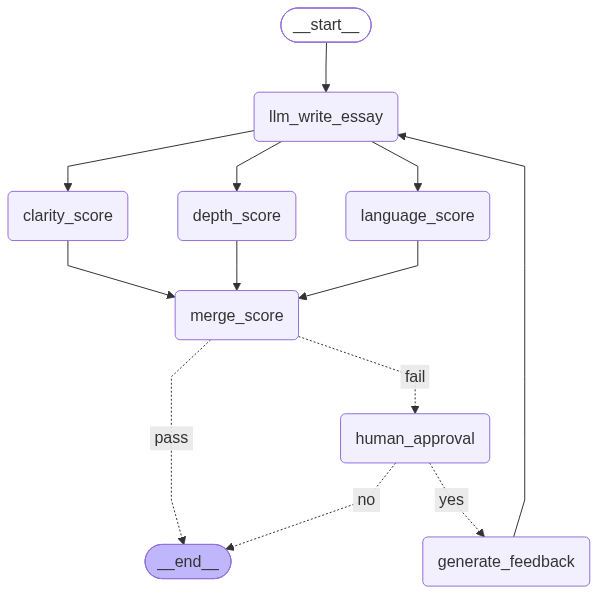

In [56]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [57]:
initial_state = {
    "topic": "Write an essay on AI emotional intelligence",
    "essay": "",
    "clarity_score": 0.0,
    "depth_score": 0.0,
    "language_score": 0.0,
    "final_evaluation_score": 0.0,
    "feedback": "",
    "approval": "",
    "attempt": 0,
    "max_attempts": 3,
}

config = {
    "configurable": {
        "thread_id": "essay-1"
    }
}

# Start the graph
for event in graph.stream(initial_state, config=config):
    print(event)

# Resume after interrupt
for event in graph.stream(
    Command(resume="yes"),
    config=config
):
    print(event)

Running write_essay | Attempt: 0
{'llm_write_essay': {'essay': 'I don’t have your original essay or the exact feedback, so I can’t rewrite that specific version yet. If you paste the essay and the comments you received, I’ll revise it precisely to address the notes. In the meantime, here’s a fresh, polished essay on AI emotional intelligence that you can use as a strong, well-structured version or as a basis for your rewrite.\n\nAI emotional intelligence: can machines understand and respond to feelings?\n\nArtificial intelligence has moved well beyond crunching numbers and playing games. Today, researchers talk about AI emotional intelligence—the capacity of machines to recognize, interpret, simulate, and respond to human emotions in ways that feel natural and constructive. This is not a claim that machines feel emotions the way humans do; rather, it is the ability to read affective cues, infer needs, and adapt behavior to improve interactions. As promising as this sounds, AI emotional